# E.2 Find a trait region with local ancestry

Suppose a risk allele is more common in one ancestral source. We may not have typed that allele, but a local ancestry block can mark its region. Which part of a person's ancestry matters for the trait: the genome-wide fraction or ancestry at one locus?

For person $i$, let $q_i$ be the genome-wide fraction from source 1 and $A_{i\ell}\in\{0,1,2\}$ the number of source-1 copies at locus $\ell$. A simple disease model is

$$Y_i\mid A_{i\ell},q_i\sim\operatorname{Bernoulli}(\pi_i),\qquad \operatorname{logit}(\pi_i)=\alpha+\beta_\ell A_{i\ell}+\gamma q_i.$$

The local coefficient asks whether ancestry at this locus adds information beyond the person's overall ancestry. This is a model of association, not proof that local ancestry is causal.


## A small constructed scan

We will simulate 800 people and 12 candidate loci. Only locus 6 affects disease risk in the data-generating model. Local ancestry counts are supplied as if already inferred; this notebook does not rerun the chromosome-painting HMM. Before fitting, we expect a positive coefficient near locus 6 and coefficients near zero elsewhere.


In [1]:
library(hpgR)

set.seed(6206)
people <- 800
loci <- 12
target <- 6
simulated <- simulateAncestryAssociation(people, loci, target)
global <- simulated$global
local <- simulated$local
disease_probability <- simulated$disease_probability
disease <- simulated$disease
stopifnot(all(local %in% 0:2), all(disease %in% 0:1))

Fit the same model at every locus. The known target is used only to check the result after fitting; it is not passed to the fitting function.


true_locus largest_estimate 
               6                6

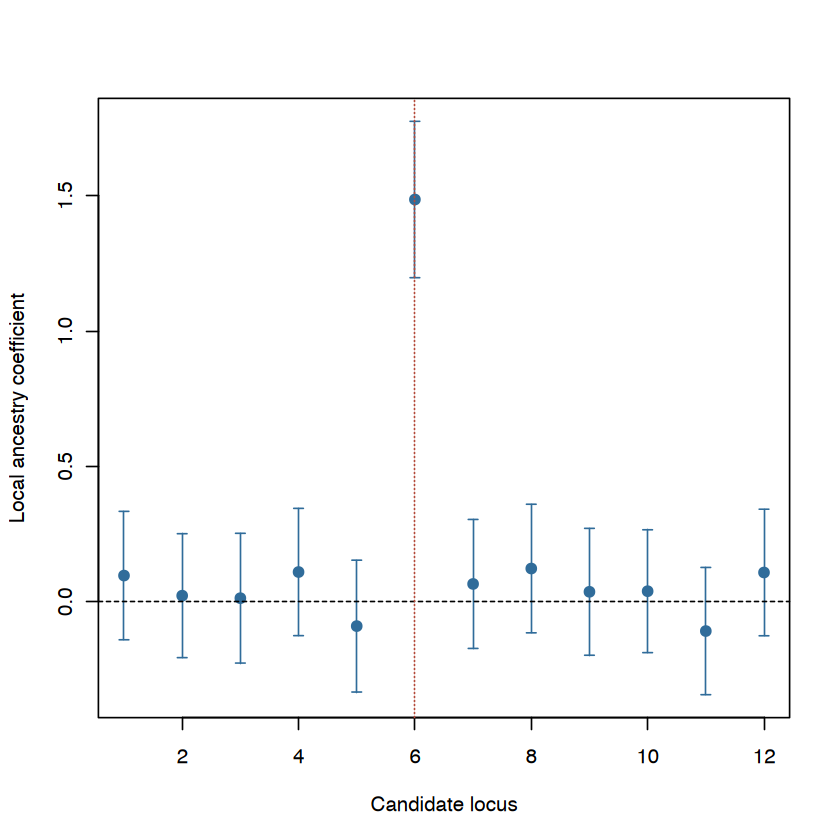

In [2]:
result <- fitAncestryAssociation(disease, local, global)
estimate <- result[, 1]
se <- result[, 2]
plot(seq_len(loci), estimate, pch = 19, col = '#306C9A',
     ylim = range(estimate + 2 * se, estimate - 2 * se),
     xlab = 'Candidate locus', ylab = 'Local ancestry coefficient')
arrows(seq_len(loci), estimate - 2 * se, seq_len(loci), estimate + 2 * se,
       angle = 90, code = 3, length = 0.04, col = '#306C9A')
abline(h = 0, lty = 2)
abline(v = target, col = '#B44A3A', lty = 3)
c(true_locus = target, largest_estimate = which.max(estimate))

The vertical bars show approximately two standard errors, not a genome-wide significance threshold. The target effect is real by construction. In observational data, local ancestry could tag a region that contains the variant; it does not identify the variant or molecular mechanism. Closely linked ancestry states would make a broader peak than these independent toy loci.

## What to remember

Global ancestry describes a person; local ancestry varies along the chromosome. A local term that predicts disease beyond the global baseline points to a region for follow-up. A candidate region is not a causal allele.

**Sources.** The model follows the lecture's admixture-mapping explanation and Patterson et al. (2004), *American Journal of Human Genetics*. The 800-person, 12-locus data are original simulation values (seed 6206); unlike the published scans, loci are independent for clarity.
